# 03 · Performance metrics

KPIs are computed per **device x period** (pre/post rollout); device is the unit of analysis. Each KPI maps to one of
the engineering questions.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

In [2]:
from src.performance_metrics import METRICS, device_period_kpis, fleet_kpis_by_version, fleet_timeseries
pd.DataFrame([vars(m) for m in METRICS])

,name,label,higher_is_better,guardrail,question
0,fw_errors_per_100,Firmware errors / 100 intervals,False,True,Have hardware error rates increased?
1,uptime_pct,Uptime %,True,True,Has device uptime improved or declined?
2,reboots_per_100,Reboots / 100 intervals,False,True,Has device uptime improved or declined?
3,sensor_jitter,Sensor jitter (rel. step-to-step change),False,False,Are sensor readings more stable?
4,mean_rms,Mean vibration RMS (g),False,False,Are sensor readings consistent / calibrated?
5,alarm_rate_pct,Vibration alarm rate %,False,False,Are sensor readings more stable?
6,p50_response_ms,Median response time (ms),False,False,Has response time changed?
7,p95_response_ms,P95 response time (ms),False,True,Has response time changed?


In [3]:
tel = pd.read_parquet(P / "telemetry.parquet")
kpis = device_period_kpis(tel)
kpis.head()

,device_id,period,group,hw_revision,region,firmware_version,n_intervals,fw_errors,reboots,uptime_pct,mean_rms,rms_cv,alarm_rate_pct,hw_fault_rate_pct,p50_response_ms,p95_response_ms,mean_response_ms,sensor_jitter,fw_errors_per_100,reboots_per_100
0,DEV-0001,post,treatment,A,EU-West,2.0.0,120,3,0,100.0,0.1466,0.0728,0.0,0.0,41.7996,44.4130,41.7785,0.0043,2.5000,0.0
1,DEV-0001,pre,treatment,A,EU-West,1.0.0,120,3,0,100.0,0.1280,0.0195,0.0,0.0,48.2882,52.0092,48.4572,0.0071,2.5000,0.0
2,DEV-0002,post,treatment,A,NA-East,2.0.0,120,1,0,100.0,0.1496,0.0041,0.0,0.0,37.1569,40.1114,37.3317,0.0028,0.8333,0.0
3,DEV-0002,pre,treatment,A,NA-East,1.0.0,120,7,0,100.0,0.1500,0.0057,0.0,0.0,42.5635,45.7369,42.5603,0.0066,5.8333,0.0
4,DEV-0003,post,control,A,NA-East,1.0.0,120,7,0,100.0,0.1535,0.0050,0.0,0.0,41.7775,45.2612,42.1137,0.0056,5.8333,0.0


### Headline table by firmware version
A pooled table like this is what dashboards usually show first. It mixes hardware revisions and ignores time trends, so
treat it as descriptive only.

In [4]:
fleet_kpis_by_version(tel)

,firmware_version,devices,device_hours,fw_errors_per_100,reboots_per_100,uptime_pct,alarm_rate_pct,hw_fault_rate_pct,p50_response_ms,p95_response_ms
0,1.0.0,152,4240.0,4.5008,0.1061,99.5954,1.9143,0.6682,44.7893,54.5155
1,2.0.0,92,1840.0,4.7736,0.2899,99.3643,3.1793,0.9149,43.2299,61.1420


In [5]:
kpis.groupby(["hw_revision", "group", "period"])[[m.name for m in METRICS]].mean()

fw_errors_per_100  uptime_pct  reboots_per_100  sensor_jitter  mean_rms  alarm_rate_pct  p50_response_ms  p95_response_ms
hw_revision group     period                                                                                                                           
A           control   post               5.1744     99.3179           0.1163         0.0140    0.0895          3.1008          44.3072          47.4764
                      pre                4.5349     99.9232           0.1163         0.0131    0.0890          0.7946          44.2084          47.2012
            treatment post               2.9924     99.4004           0.1010         0.0062    0.0916          2.8157          40.4695          43.2899
                      pre                4.3182     99.2803           0.0631         0.0145    0.0886          2.8914          45.9621          49.2399
B           control   post               3.8725     99.9770           0.0490         0.0129    0.0864          0.0000          45.8618          49.0256
                      pre                4.9020     99.9686           0.0490         0.0127    0.0854          0.0000          45.9700          49.1946
            treatment post               9.2949     99.2726           0.7692         0.0066    0.0914          4.1026          55.2612          59.0360
                      pre                3.9423     99.8182           0.2564         0.0138    0.0837          1.8269          45.3078          48.6583

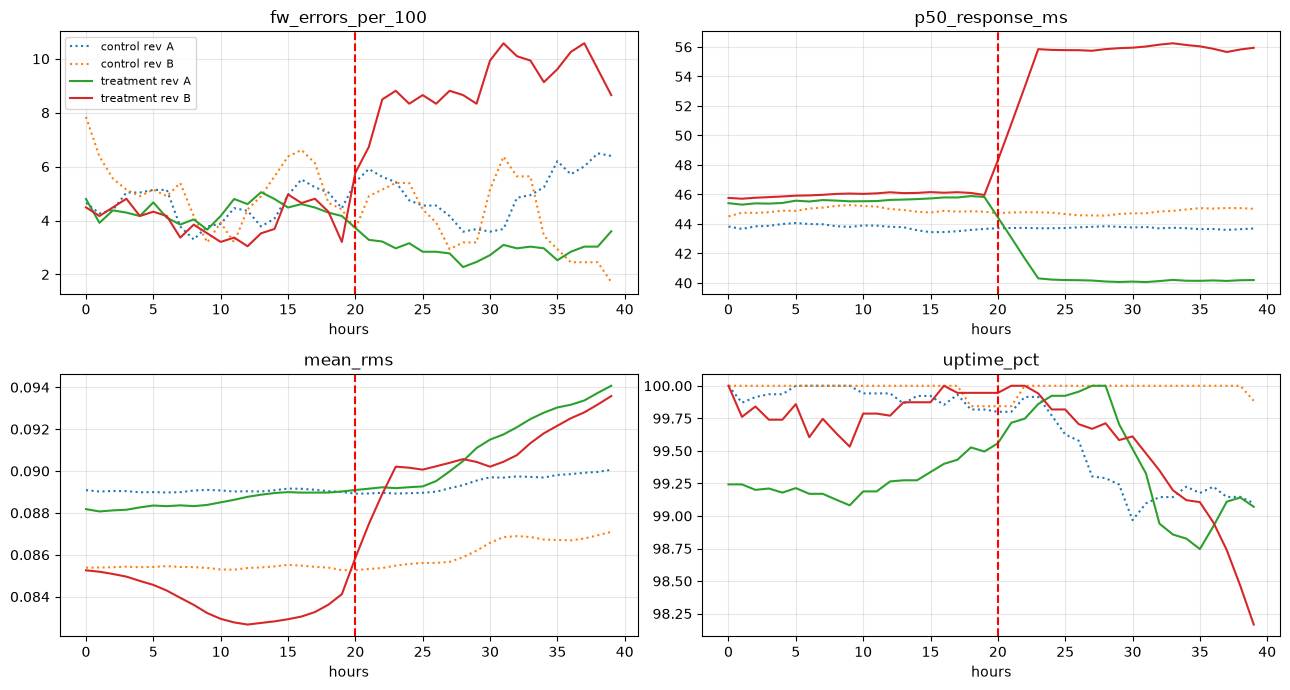

In [6]:
ts = fleet_timeseries(tel, 6)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, m in zip(axes.flat, ["fw_errors_per_100", "p50_response_ms", "mean_rms", "uptime_pct"]):
    for (grp, rev), g in ts.groupby(["group", "hw_revision"]):
        ax.plot(g.bucket / 6, g[m].rolling(4, min_periods=1).mean(), label=f"{grp} rev {rev}",
                ls="-" if grp == "treatment" else ":")
    ax.axvline(20, color="red", ls="--"); ax.set_title(m); ax.set_xlabel("hours")
axes[0, 0].legend(fontsize=8); plt.tight_layout()

Even before formal tests, the rev-B treatment lines move after hour 20 (rollout), while the control lines and rev A
do not move the same way. Notebook 04 quantifies this.